# Character BiLSTM adversarial training (MODEL 2)

1. Train MODEL 2 on `train + bilstm_adv_train` (edited, non-duplicate adversarial rows labelled phishing). Validation stays the original `val.csv`.
2. Attack MODEL 2 white-box on the test set with the same attack, budget and validator as MODEL 1.
3. Evaluate MODEL 1 and MODEL 2 on `test_original` and `test_original + test_adversarial` (attacks from MODEL 1 and from MODEL 2), by group (all / web.app / other), like `cnn_model2.ipynb`.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from torch.utils.tensorboard import SummaryWriter
from tqdm.auto import tqdm

sys.path.append('../src')
import generate_bilstm_adversarial as attack_impl
from evaluate import evaluate, adversarial_rows, attack_summary, group_evaluation, save_preds
from validate_adv import invalid_reason

/opt/pytorch/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## Configuration
- same training recipe as `bilstm.ipynb` (AdamW, 6% warmup + linear decay, grad clipping, early stopping on validation loss)
- MODEL 2 has the same architecture as MODEL 1 (read from its checkpoint)

In [2]:
SEED = 42
BATCH_SIZE = 256
LR = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 20
EVAL_EVERY = 500
PATIENCE = 3
MIN_DELTA = 1e-4
FORCE_RETRAIN = False  # reuse the saved MODEL 2 checkpoint if present
THRESHOLD = 0.5
TOP_POSITIONS = 3
ATTACK_BATCH = 64

DATA, RESULTS, MODELS = Path('../data'), Path('../results'), Path('../models')
M1_CKPT = MODELS / 'bilstm_model1.pt'
M2_CKPT = MODELS / 'bilstm_model2.pt'
ADV_TRAIN = DATA / 'bilstm_adv_train.csv'          # MODEL 1 attack on train
ADV_TEST_M1 = DATA / 'bilstm_adv_test.csv'         # MODEL 1 attack on test
ADV_TEST_M2 = DATA / 'bilstm_m2_adv_test.csv'      # MODEL 2 attack on test (made below)
ADV_TEST_M2_PARTIAL = DATA / 'bilstm_m2_adv_test_partial.csv'
TRAIN_LOG = RESULTS / 'bilstm_model2_train_log.csv'
for p in (RESULTS, MODELS):
    p.mkdir(parents=True, exist_ok=True)

config, vocab = attack_impl.load_config()
MAX_LEN, K = config['max_len'], config['budget']
CHAR_TO_IDX = {c: i for i, c in enumerate(vocab['index_to_string'])}
PAD_IDX, UNK_IDX = vocab['pad_idx'], vocab['unk_idx']

device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
use_amp = device.type == 'cuda'
torch.manual_seed(SEED)
np.random.seed(SEED)
print('device:', device, '| max_len:', MAX_LEN, '| k:', K)

device: cuda | max_len: 256 | k: 3


## Data
`train_aug` = original train + edited, non-duplicate adversarial URLs from MODEL 1 (label 0 = phishing).

In [3]:
splits = attack_impl.load_splits()
train_df, val_df, test_df = splits['train'], splits['val'], splits['test']

adv_train = pd.read_csv(ADV_TRAIN, keep_default_na=False)
adv_train['duplicate'] = adv_train['duplicate'].astype(str).eq('True')
extra = adversarial_rows(adv_train)[['URL', 'label']]
train_aug = pd.concat([train_df[['URL', 'label']], extra], ignore_index=True)

print(f'train_original {len(train_df)} -> augmented {len(train_aug)} (+{len(extra)} adversarial)')
print('phishing share in train:', round((train_df.label == 0).mean(), 4), '->', round((train_aug.label == 0).mean(), 4))
print('adversarial URLs also in test_original (check, expect 0):', len(set(extra.URL) & set(test_df.URL)))

train_original 185397 -> augmented 199208 (+13811 adversarial)
phishing share in train: 0.4183 -> 0.4586
adversarial URLs also in test_original (check, expect 0): 0


In [4]:
class URLDataset(Dataset):
    def __init__(self, df):
        self.urls = df['URL'].astype(str).tolist()
        self.labels = df['label'].astype('int64').tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        ids = [CHAR_TO_IDX.get(c, UNK_IDX) for c in self.urls[i][:MAX_LEN]]
        return torch.tensor(ids, dtype=torch.long), self.labels[i]


def collate(batch):
    ids, labels = zip(*batch)
    lengths = torch.tensor([len(x) for x in ids], dtype=torch.long)
    return pad_sequence(ids, batch_first=True, padding_value=PAD_IDX), lengths, torch.tensor(labels, dtype=torch.long)


train_set, val_set = URLDataset(train_aug), URLDataset(val_df)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader = DataLoader(val_set, batch_size=512, shuffle=False, collate_fn=collate)

# MODEL 1 (frozen) and the MODEL 2 architecture, taken from MODEL 1's checkpoint
model1 = attack_impl.load_model(M1_CKPT, len(CHAR_TO_IDX), PAD_IDX, device)
state1 = torch.load(M1_CKPT, map_location='cpu', weights_only=True)
ARCH = dict(
    embedding_dim=state1['embedding.weight'].shape[1],
    hidden_dim=state1['lstm.weight_ih_l0'].shape[0] // 4,
    num_layers=1 + max(int(k.split('_l')[-1]) for k in state1 if k.startswith('lstm.weight_ih_l') and not k.endswith('reverse')),
)
print('architecture:', ARCH)

architecture: {'embedding_dim': 64, 'hidden_dim': 128, 'num_layers': 2}


# Train MODEL 2
Class 0 is phishing, `softmax(logits)[:, 0]` is `p_phish`. The checkpoint with the lowest validation loss is saved.

In [5]:
loss_fn = nn.CrossEntropyLoss()


@torch.no_grad()
def run_eval(net, loader):
    net.eval()
    total, probs = 0.0, []
    for ids, lengths, labels in loader:
        ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)
        logits = net(ids, lengths).float()
        total += loss_fn(logits, labels).item() * len(labels)
        probs.append(torch.softmax(logits, dim=-1)[:, 0].cpu())
    return total / len(loader.dataset), torch.cat(probs).numpy()


def train_model2():
    net = attack_impl.BiLSTMClassifier(len(CHAR_TO_IDX), PAD_IDX, dropout=0.3, **ARCH).to(device)
    optimizer = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    total_steps = MAX_EPOCHS * len(train_loader)
    warmup = int(0.06 * total_steps)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda s: s / max(1, warmup) if s < warmup else max(0.0, (total_steps - s) / max(1, total_steps - warmup)),
    )
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    writer = SummaryWriter('../runs/bilstm_model2')
    log, running, step, best_val, bad, stopped = [], [], 0, float('inf'), 0, False

    for epoch in range(1, MAX_EPOCHS + 1):
        for ids, lengths, labels in tqdm(train_loader, desc=f'epoch {epoch}'):
            net.train()
            ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                loss = loss_fn(net(ids, lengths), labels)
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            step += 1
            running.append(loss.item())

            if step % EVAL_EVERY == 0:
                val_loss, p_val = run_eval(net, val_loader)
                m = evaluate(val_set.labels, p_val)
                improved = val_loss < best_val - MIN_DELTA
                if improved:
                    best_val, bad = val_loss, 0
                    torch.save(net.state_dict(), M2_CKPT)
                else:
                    bad += 1
                log.append({'step': step, 'epoch': epoch, 'train_loss': float(np.mean(running)), 'val_loss': val_loss,
                            'val_acc': m['accuracy'], 'val_recall': m['recall'], 'val_f1': m['f1'], 'best': improved})
                running = []
                pd.DataFrame(log).to_csv(TRAIN_LOG, index=False)
                writer.add_scalars('loss', {'train': log[-1]['train_loss'], 'val': val_loss}, step)
                print(f"step {step} | train {log[-1]['train_loss']:.4f} | val {val_loss:.4f} | recall {m['recall']:.4f}{' *' if improved else ''}")
                if bad >= PATIENCE:
                    stopped = True
                    break
        if stopped:
            print('early stopping')
            break
    writer.close()


if M2_CKPT.exists() and not FORCE_RETRAIN:
    print('reusing', M2_CKPT)
else:
    train_model2()

model2 = attack_impl.load_model(M2_CKPT, len(CHAR_TO_IDX), PAD_IDX, device)  # best checkpoint, frozen
models = {'MODEL 1': model1, 'MODEL 2': model2}
predictors = {n: attack_impl.make_predictor(m, CHAR_TO_IDX, UNK_IDX, PAD_IDX, MAX_LEN, device) for n, m in models.items()}

epoch 1:   0%|          | 0/779 [00:00<?, ?it/s]

step 500 | train 0.4161 | val 0.3048 | recall 0.7749 *


epoch 2:   0%|          | 0/779 [00:00<?, ?it/s]

step 1000 | train 0.2749 | val 0.2875 | recall 0.7945 *
step 1500 | train 0.2614 | val 0.2648 | recall 0.7752 *


epoch 3:   0%|          | 0/779 [00:00<?, ?it/s]

step 2000 | train 0.2537 | val 0.2636 | recall 0.7867 *


... (6 outputs left out)

epoch 7:   0%|          | 0/779 [00:00<?, ?it/s]

step 5000 | train 0.2220 | val 0.2560 | recall 0.8120


epoch 8:   0%|          | 0/779 [00:00<?, ?it/s]

step 5500 | train 0.2205 | val 0.2534 | recall 0.8038
step 6000 | train 0.2141 | val 0.2546 | recall 0.8169
early stopping


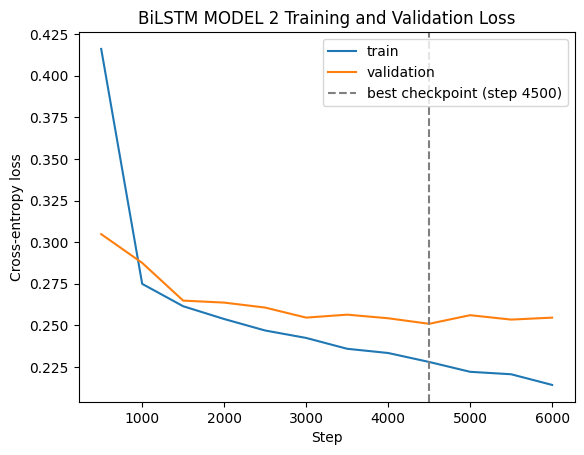

In [6]:
log_df = pd.read_csv(TRAIN_LOG)
best = log_df.loc[log_df['val_loss'].idxmin()]
plt.plot(log_df['step'], log_df['train_loss'], label='train')
plt.plot(log_df['step'], log_df['val_loss'], label='validation')
plt.axvline(best['step'], ls='--', c='grey', label=f"best checkpoint (step {int(best['step'])})")
plt.xlabel('Step')
plt.ylabel('Cross-entropy loss')
plt.title('BiLSTM MODEL 2 Training and Validation Loss')
plt.legend()
plt.savefig(RESULTS / 'bilstm_model2_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()

# Adversarial attack on MODEL 2
- targets: test phishing URLs that are valid originals and that MODEL 2 detects (`p_phish >= 0.5`)
- same attack, budget `K` and validator as MODEL 1; progress is appended to a partial csv so the cell can resume

In [7]:
p2 = predictors['MODEL 2']
embedding2 = model2.embedding.weight
valid_embedding_ids = torch.tensor([i for c, i in CHAR_TO_IDX.items() if c not in {'<PAD>', '<UNK>'}], dtype=torch.long, device=device)

phish = attack_impl.drop_invalid_originals(test_df[test_df.label == 0]).copy()
phish['p_clean'] = p2(phish.URL.tolist())
targets_m2 = phish[phish.p_clean >= THRESHOLD].reset_index(drop=True)
print(f'phishing {len(phish)} | missed by MODEL 2 {len(phish) - len(targets_m2)} | to attack {len(targets_m2)}')

if ADV_TEST_M2_PARTIAL.exists():
    done = pd.read_csv(ADV_TEST_M2_PARTIAL, keep_default_na=False)
    print('resuming:', len(done), 'URLs already attacked')
else:
    done = pd.DataFrame(columns=['orig_URL', 'URL'])
    done.to_csv(ADV_TEST_M2_PARTIAL, index=False)

todo = targets_m2[~targets_m2.URL.isin(done.orig_URL)]
t0 = time.time()
for start in tqdm(range(0, len(todo), ATTACK_BATCH), desc='attack MODEL 2'):
    chunk = todo.iloc[start:start + ATTACK_BATCH]
    adv = attack_impl.attack_batch(
        chunk.URL.tolist(), chunk.p_clean.tolist(), model2, embedding2, valid_embedding_ids,
        CHAR_TO_IDX, UNK_IDX, PAD_IDX, MAX_LEN, K, TOP_POSITIONS, device, p2,
    )
    pd.DataFrame({'orig_URL': chunk.URL.values, 'URL': adv}).to_csv(ADV_TEST_M2_PARTIAL, mode='a', header=False, index=False)
print('seconds per URL:', round((time.time() - t0) / max(1, len(todo)), 4))

phishing 9694 | missed by MODEL 2 1818 | to attack 7876


attack MODEL 2:   0%|          | 0/124 [00:00<?, ?it/s]

seconds per URL: 0.0734


In [8]:
attack_map = dict(pd.read_csv(ADV_TEST_M2_PARTIAL, keep_default_na=False).values)
missing = targets_m2[~targets_m2.URL.isin(attack_map)]
assert missing.empty, f'{len(missing)} targets have no attack result; rerun the attack cell'

adv_m2 = pd.DataFrame({'orig_URL': targets_m2.URL.values, 'URL': targets_m2.URL.map(attack_map).values,
                       'label': 0, 'p_clean': targets_m2.p_clean.values})
adv_m2['p_adv'] = p2(adv_m2.URL.tolist())
adv_m2['n_edits'] = [attack_impl.edit_distance(o, a) for o, a in zip(adv_m2.orig_URL, adv_m2.URL)]
adv_m2['flipped'] = adv_m2.p_adv < THRESHOLD

reasons = pd.Series([invalid_reason(o, a, K) for o, a in zip(adv_m2.orig_URL, adv_m2.URL)])
print(reasons.replace('', 'valid').value_counts())
assert (reasons == '').all(), 'attack produced invalid URLs'
assert (adv_m2.n_edits <= K).all()

adv_m2['duplicate'] = (adv_m2.n_edits > 0) & (adv_m2.URL.isin(test_df.URL) | adv_m2.URL.duplicated())
adv_m2.to_csv(ADV_TEST_M2, index=False)
ADV_TEST_M2_PARTIAL.unlink()

# MODEL 1's test attack, from bilstm_generate_examples_test.ipynb
adv_m1 = pd.read_csv(ADV_TEST_M1, keep_default_na=False)
adv_m1['duplicate'] = adv_m1['duplicate'].astype(str).eq('True')

summaries = {}
for name, a in (('adv(M1)', adv_m1), ('adv(M2)', adv_m2)):
    s = attack_summary(a, K)
    summaries[name] = s
    print(name, {k: s[k] for k in ('attacked', 'flipped', 'edited_not_flipped', 'not_edited', 'duplicates_dropped')},
          '| success within k:', round(s['success_within_edits'][K], 4))
(RESULTS / 'bilstm_m2_adv_test_summary.json').write_text(json.dumps(summaries['adv(M2)'], indent=1))

valid    7876
Name: count, dtype: int64
adv(M1) {'attacked': 7876, 'flipped': 739, 'edited_not_flipped': 6393, 'not_edited': 744, 'duplicates_dropped': 687} | success within k: 0.0938
adv(M2) {'attacked': 7876, 'flipped': 65, 'edited_not_flipped': 6686, 'not_edited': 1125, 'duplicates_dropped': 757} | success within k: 0.0083


646

# Evaluation on test set
- Sets 2 and 3 are phishing-heavier than set 1, so recall rises for every model on them. Compare models *within* a set.
- `fpr` on set 1 is the cost of adversarial training.
- web.app is all phishing, only look at recall-type metrics (`recall`, `adversarial_recall`, `robust_recall`, `attack_success_rate`); `fpr`, precision, F1 and the AUCs are `nan`.
- `adversarial_recall`: share of the edited, non-duplicate adversarial URLs the model still detects.
- `attack_success_rate`: has a different denominator for each model (the phishing URLs that model detected clean), so it can't be compared across models.
- `robust_recall`: share of all true-phishing test URLs detected both before and after the attack (fixed denominator), so MODEL 1 and MODEL 2 are directly comparable.

In [9]:
def eval_groups(p, adv):
    return group_evaluation(test_df, p(test_df.URL.tolist()), adv, p(adv.orig_URL.tolist()), p(adv.URL.tolist()))


mkey = {'MODEL 1': 'm1', 'MODEL 2': 'm2'}
parts_ = []
for mn, p in predictors.items():
    save_preds(RESULTS / f'bilstm_{mkey[mn]}_test_preds.csv', test_df.URL, test_df.label, p(test_df.URL.tolist()))
    for src, adv in (('MODEL 1', adv_m1), ('MODEL 2', adv_m2)):
        r = eval_groups(p, adv)
        r['fpr'] = r['confusion_matrix'].map(
            lambda c: c[1][0] / sum(c[1]) if isinstance(c, list) and sum(c[1]) else float('nan'))
        r.insert(0, 'attacks from', src)
        r.insert(0, 'model', mn)
        parts_.append(r)
res = pd.concat(parts_, ignore_index=True)

cols = ['accuracy', 'precision', 'recall', 'f1', 'fpr', 'roc_auc', 'attack_success_rate', 'n_attempts',
        'adversarial_recall', 'robust_recall', 'delta_recall']

# set 1 (test_original): identical for both attack sources, so show it once
set1 = res[(res['test_set'] == 'test_original') & (res['attacks from'] == 'MODEL 1')]
display(set1.set_index(['model', 'group'])[cols[:6]].round(4))

# sets 2 and 3: test_original + adversarial rows from MODEL 1 / MODEL 2
mixed = res[res['test_set'] != 'test_original']
display(mixed.set_index(['model', 'attacks from', 'group'])[cols].round(4))

res.drop(columns='confusion_matrix').to_csv(RESULTS / 'bilstm_group_eval.csv', index=False)

accuracy  precision  recall      f1     fpr  roc_auc
model   group                                                        
MODEL 1 all        0.9077     0.9607  0.8125  0.8804  0.0239   0.9445
        web.app       NaN        NaN  1.0000     NaN     NaN      NaN
        other      0.8782     0.8758  0.5554  0.6797  0.0239   0.8686
MODEL 2 all        0.9066     0.9578  0.8125  0.8792  0.0257   0.9440
        web.app       NaN        NaN  1.0000     NaN     NaN      NaN
        other      0.8768     0.8675  0.5554  0.6772  0.0257   0.8671

accuracy  precision  recall      f1     fpr  \
model   attacks from group                                                  
MODEL 1 MODEL 1      all        0.9028     0.9768  0.8416  0.9042  0.0239   
                     web.app       NaN        NaN  0.9989     NaN     NaN   
                     other      0.8499     0.9052  0.5470  0.6819  0.0239   
        MODEL 2      all        0.9238     0.9772  0.8788  0.9254  0.0239   
                     web.app       NaN        NaN  1.0000     NaN     NaN   
                     other      0.8812     0.9119  0.6365  0.7497  0.0239   
MODEL 2 MODEL 1      all        0.9269     0.9763  0.8873  0.9297  0.0257   
                     web.app       NaN        NaN  1.0000     NaN     NaN   
                     other      0.8866     0.9163  0.6762  0.7782  0.0257   
        MODEL 2      all        0.9236     0.9755  0.8800  0.9253  0.0257   
                     web.app       NaN        NaN  1.0000     NaN     NaN   
                     other      0.8809     0.9062  0.6404  0.7504  0.0257   

                              roc_auc  attack_success_rate  n_attempts  \
model   attacks from group                                               
MODEL 1 MODEL 1      all       0.9486               0.0938      7876.0   
                     web.app      NaN               0.0021      5605.0   
                     other     0.8546               0.3201      2271.0   
        MODEL 2      all       0.9637               0.0094      7760.0   
                     web.app      NaN               0.0000      5605.0   
                     other     0.8917               0.0339      2155.0   
MODEL 2 MODEL 1      all       0.9663               0.0001      7760.0   
                     web.app      NaN               0.0000      5605.0   
                     other     0.9032               0.0005      2155.0   
        MODEL 2      all       0.9647               0.0083      7876.0   
                     web.app      NaN               0.0000      5605.0   
                     other     0.8943               0.0286      2271.0   

                              adversarial_recall  robust_recall  delta_recall  
model   attacks from group                                                     
MODEL 1 MODEL 1      all                  0.8853         0.7362        0.0291  
                     web.app              0.9976         0.9979       -0.0011  
                     other                0.5245         0.3776       -0.0084  
        MODEL 2      all                  0.9860         0.8049        0.0663  
                     web.app              1.0000         1.0000        0.0000  
                     other                0.9266         0.5375        0.0811  
MODEL 2 MODEL 1      all                  0.9998         0.8124        0.0748  
                     web.app              1.0000         1.0000        0.0000  
                     other                0.9993         0.5551        0.1208  
        MODEL 2      all                  0.9893         0.8058        0.0676  
                     web.app              1.0000         1.0000        0.0000  
                     other                0.9441         0.5395        0.0850